In [ ]:

!pip install -q tensorflow scikit-learn seaborn kagglehub

import os, random, json, math, time, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.applications import ResNet50, EfficientNetB0, VGG16
from tensorflow.keras.applications.resnet50 import preprocess_input as pp_resnet
from tensorflow.keras.applications.efficientnet import preprocess_input as pp_efficientnet
from tensorflow.keras.applications.vgg16 import preprocess_input as pp_vgg16

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix,
                              f1_score, precision_score, recall_score,
                              roc_auc_score, roc_curve, auc)
from sklearn.preprocessing import label_binarize

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU tersedia:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.21.0
GPU tersedia: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

BASE_DIR    = '/content/drive/MyDrive/Tesis_HAM10000'
MODEL_DIR   = f'{BASE_DIR}/models'
BACKUP_DIR  = f'{BASE_DIR}/backups'
RESULTS_DIR = f'{BASE_DIR}/results'
FIGS_DIR    = f'{BASE_DIR}/figures'

for d in [MODEL_DIR, BACKUP_DIR, RESULTS_DIR, FIGS_DIR]:
    os.makedirs(d, exist_ok=True)

print("direktori siap")
for d in [MODEL_DIR, BACKUP_DIR, RESULTS_DIR, FIGS_DIR]:
    print(" -", d)


Mounted at /content/drive
direktori siap
 - /content/drive/MyDrive/Tesis_HAM10000/models
 - /content/drive/MyDrive/Tesis_HAM10000/backups
 - /content/drive/MyDrive/Tesis_HAM10000/results
 - /content/drive/MyDrive/Tesis_HAM10000/figures


In [ ]:

from google.colab import files
files.upload()
!mkdir -p ~/.kaggle && cp kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d kmader/skin-cancer-mnist-ham10000 -p /content/ham10000 --unzip
dataset_path = "/content/ham10000"


Saving kaggle.json to kaggle.json
Dataset URL: https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000
License(s): CC-BY-NC-SA-4.0
100% 5.20G/5.20G [00:47<00:00, 118MB/s]



In [ ]:


metadata_csv = glob.glob(os.path.join(dataset_path, "**", "*metadata*.csv"), recursive=True)[0]
image_dirs = [d for d in glob.glob(os.path.join(dataset_path, "**", "*"), recursive=True)
              if os.path.isdir(d) and any(f.endswith(('.jpg', '.jpeg')) for f in os.listdir(d)[:5] if os.path.isfile(os.path.join(d, f)))]

print("Metadata:", metadata_csv)
print("Folder gambar ditemukan:", image_dirs)

image_path_map = {}
for d in image_dirs:
    for fname in os.listdir(d):
        if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
            image_id = os.path.splitext(fname)[0]
            image_path_map[image_id] = os.path.join(d, fname)

print("Total gambar terindeks:", len(image_path_map))


Metadata: /content/ham10000/HAM10000_metadata.csv
Folder gambar ditemukan: ['/content/ham10000/HAM10000_images_part_2', '/content/ham10000/ham10000_images_part_1', '/content/ham10000/HAM10000_images_part_1', '/content/ham10000/ham10000_images_part_2']
Total gambar terindeks: 10015


Total sampel: 10015

Distribusi kelas:
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


/tmp/ipykernel_3581/880384278.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='dx', order=df['dx'].value_counts().index, palette='viridis')


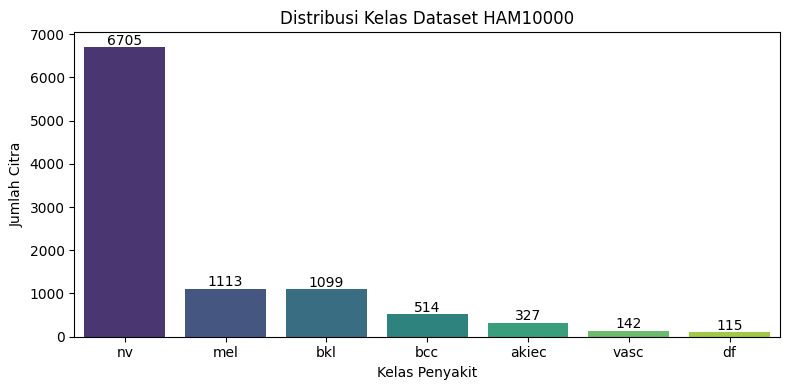

In [ ]:
df = pd.read_csv(metadata_csv)
df['path'] = df['image_id'].map(image_path_map)
df = df.dropna(subset=['path']).reset_index(drop=True)

CLASS_NAMES = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
LABEL2IDX = {c: i for i, c in enumerate(CLASS_NAMES)}
IDX2LABEL = {i: c for c, i in LABEL2IDX.items()}

df['label'] = df['dx'].map(LABEL2IDX)

print("Total sampel:", len(df))
print("\nDistribusi kelas:")
print(df['dx'].value_counts())

plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='dx', order=df['dx'].value_counts().index, palette='viridis')
plt.title('Distribusi Kelas Dataset HAM10000')
plt.xlabel('Kelas Penyakit')
plt.ylabel('Jumlah Citra')
for i, v in enumerate(df['dx'].value_counts().values):
    plt.text(i, v + 50, str(v), ha='center')
plt.tight_layout()
plt.savefig(f'{FIGS_DIR}/distribusi_kelas.png', dpi=150)
plt.show()

In [ ]:
print(df['dx_type'].value_counts())
print(f"\nProporsi histopatologi: {(df['dx_type']=='histo').mean()*100:.2f}%")


dx_type
histo        5340
follow_up    3704
consensus     902
confocal       69
Name: count, dtype: int64

Proporsi histopatologi: 53.32%


In [ ]:
lesion_df = df.groupby('lesion_id')['label'].agg(lambda x: x.mode()[0]).reset_index()

train_lesions, temp_lesions = train_test_split(
    lesion_df, test_size=0.30, stratify=lesion_df['label'], random_state=SEED
)
val_lesions, test_lesions = train_test_split(
    temp_lesions, test_size=0.50, stratify=temp_lesions['label'], random_state=SEED
)

train_df = df[df['lesion_id'].isin(train_lesions['lesion_id'])].reset_index(drop=True)
val_df   = df[df['lesion_id'].isin(val_lesions['lesion_id'])].reset_index(drop=True)
test_df  = df[df['lesion_id'].isin(test_lesions['lesion_id'])].reset_index(drop=True)

print(f"Train : {len(train_df)} citra ({len(train_lesions)} lesi)")
print(f"Val   : {len(val_df)} citra ({len(val_lesions)} lesi)")
print(f"Test  : {len(test_df)} citra ({len(test_lesions)} lesi)")

assert set(train_df.lesion_id) & set(val_df.lesion_id) == set()
assert set(train_df.lesion_id) & set(test_df.lesion_id) == set()
assert set(val_df.lesion_id) & set(test_df.lesion_id) == set()
print("\nTidak ada kebocoran lesion_id antar split. ✔")

print("\nDistribusi kelas per split (%):")
for name, d in [('Train', train_df), ('Val', val_df), ('Test', test_df)]:
    print(f"\n{name}:")
    print((d['dx'].value_counts(normalize=True) * 100).round(2))

Train : 6981 citra (5229 lesi)
Val   : 1532 citra (1120 lesi)
Test  : 1502 citra (1121 lesi)

Tidak ada kebocoran lesion_id antar split. ✔

Distribusi kelas per split (%):

Train:
dx
nv       67.08
mel      11.07
bkl      11.06
bcc       5.17
akiec     3.18
vasc      1.42
df        1.02
Name: proportion, dtype: float64

Val:
dx
nv       66.45
mel      11.29
bkl      10.44
bcc       5.35
akiec     3.46
df        1.57
vasc      1.44
Name: proportion, dtype: float64

Test:
dx
nv       66.84
mel      11.12
bkl      11.12
bcc       4.73
akiec     3.46
vasc      1.40
df        1.33
Name: proportion, dtype: float64


In [ ]:
class_weights_arr = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(len(CLASS_NAMES)),
    y=train_df['label'].values
)
class_weight_dict = {i: w for i, w in enumerate(class_weights_arr)}
print("Class weights (mengatasi ketidakseimbangan kelas):")
for i, w in class_weight_dict.items():
    print(f"  {IDX2LABEL[i]:6s}: {w:.3f}")

Class weights (mengatasi ketidakseimbangan kelas):
  akiec : 4.492
  bcc   : 2.763
  bkl   : 1.292
  df    : 14.046
  mel   : 1.290
  nv    : 0.213
  vasc  : 10.074


In [ ]:

def get_stratified_kfold_splits(dataframe, n_splits=5, seed=SEED):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    splits = []
    for fold, (train_idx, val_idx) in enumerate(skf.split(dataframe, dataframe['label'])):
        splits.append((dataframe.iloc[train_idx].reset_index(drop=True),
                        dataframe.iloc[val_idx].reset_index(drop=True)))
    return splits



In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = len(CLASS_NAMES)
AUTOTUNE = tf.data.AUTOTUNE

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.15),
], name="augmentation")


def load_and_decode(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    return img, label


def make_dataset(dataframe, preprocess_fn, training=False, batch_size=BATCH_SIZE):
    paths = dataframe['path'].values
    labels = tf.keras.utils.to_categorical(dataframe['label'].values, num_classes=NUM_CLASSES)

    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_and_decode, num_parallel_calls=AUTOTUNE)

    if training:
        ds = ds.shuffle(buffer_size=len(dataframe), seed=SEED)
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)

    ds = ds.map(lambda x, y: (preprocess_fn(x), y), num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size)
    ds = ds.prefetch(AUTOTUNE)
    return ds


In [ ]:
def build_model(base_arch_fn, input_shape=(224, 224, 3), num_classes=NUM_CLASSES,
                 fine_tune_at=None):
    base_model = base_arch_fn(include_top=False, weights='imagenet', input_shape=input_shape)
    base_model.trainable = fine_tune_at is not None

    if fine_tune_at is not None:
        for layer in base_model.layers[:fine_tune_at]:
            layer.trainable = False
        for layer in base_model.layers[fine_tune_at:]:
            layer.trainable = True

    inputs = layers.Input(shape=input_shape)
    x = base_model(inputs, training=False if fine_tune_at is None else None)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(num_classes, activation='softmax')(x)

    model = models.Model(inputs, outputs)
    return model, base_model


MODEL_CONFIGS = {
    'ResNet50': {'fn': ResNet50, 'preprocess': pp_resnet},
    'EfficientNetB0': {'fn': EfficientNetB0, 'preprocess': pp_efficientnet},
    'VGG16': {'fn': VGG16, 'preprocess': pp_vgg16},
}

for name, cfg in MODEL_CONFIGS.items():
    tmp = cfg['fn'](include_top=False, weights=None, input_shape=(224, 224, 3))
    n_layers = len(tmp.layers)
    cfg['n_layers'] = n_layers
    cfg['fine_tune_at'] = int(n_layers * 0.7)
    print(f"{name}: total {n_layers} layer, fine-tune mulai layer ke-{cfg['fine_tune_at']}")
    del tmp

ResNet50: total 175 layer, fine-tune mulai layer ke-122
EfficientNetB0: total 237 layer, fine-tune mulai layer ke-165
VGG16: total 19 layer, fine-tune mulai layer ke-13


In [ ]:
EPOCHS_STAGE1 = 15
EPOCHS_STAGE2 = 20
LR_STAGE1 = 1e-3
LR_STAGE2 = 1e-5


def get_callbacks(model_name, stage_tag, monitor_ckpt_path, backup_dir):
    return [
        callbacks.EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7),
        callbacks.ModelCheckpoint(monitor_ckpt_path, monitor='val_loss',
                                   save_best_only=True, verbose=0),
        callbacks.BackupAndRestore(backup_dir=backup_dir),
    ]


def final_model_path(model_name):
    return f'{MODEL_DIR}/final_{model_name}.keras'


def train_one_architecture(model_name):
    fpath = final_model_path(model_name)
    if os.path.exists(fpath):
        print(f"'{model_name}' sudah pernah selesai dilatih sebelumnya. Memuat model dari Drive, tidak dilatih ulang.")
        model = tf.keras.models.load_model(fpath)
        history_path = f'{RESULTS_DIR}/{model_name}_history.json'
        history = json.load(open(history_path)) if os.path.exists(history_path) else None
        cfg = MODEL_CONFIGS[model_name]
        test_ds = make_dataset(test_df, cfg['preprocess'], training=False)
        return model, history, test_ds

    print(f"\n{'='*70}\nTRAINING: {model_name}\n{'='*70}")
    cfg = MODEL_CONFIGS[model_name]

    train_ds = make_dataset(train_df, cfg['preprocess'], training=True)
    val_ds   = make_dataset(val_df, cfg['preprocess'], training=False)
    test_ds  = make_dataset(test_df, cfg['preprocess'], training=False)


    model, base_model = build_model(cfg['fn'], fine_tune_at=None)
    model.compile(
        optimizer=optimizers.Adam(learning_rate=LR_STAGE1),
        loss='categorical_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC(name='auc', multi_label=True)]
    )
    print(f"-- Tahap 1 ({model_name}): otomatis resume --")
    hist1 = model.fit(
        train_ds, validation_data=val_ds, epochs=EPOCHS_STAGE1,
        class_weight=class_weight_dict,
        callbacks=get_callbacks(
            model_name, "stage1",
            monitor_ckpt_path=f'{MODEL_DIR}/best_{model_name}_stage1.keras',
            backup_dir=f'{BACKUP_DIR}/{model_name}_stage1'
        ),
        verbose=1
    )

    # --- Tahap 2: Selective fine-tuning (unfreeze layer akhir) ---
    fine_tune_at = cfg['fine_tune_at']
    base_model.trainable = True
    for layer in base_model.layers[:fine_tune_at]:
        layer.trainable = False

    n_bn_frozen = 0
    for layer in base_model.layers[fine_tune_at:]:
        if isinstance(layer, tf.keras.layers.BatchNormalization):
            layer.trainable = False
            n_bn_frozen += 1
    print(f"-- {n_bn_frozen} layer BatchNormalization dibekukan tambahan di zona fine-tuning --")
    # <<< akhir perbaikan

    model.compile(
        optimizer=optimizers.Adam(learning_rate=LR_STAGE2),
        loss='categorical_crossentropy',
        metrics=['accuracy', tf.keras.metrics.AUC(name='auc', multi_label=True)]
    )
    print(f"-- Tahap 2 ({model_name}): jika ada backup sebelumnya, akan otomatis resume --")
    hist2 = model.fit(
        train_ds, validation_data=val_ds, epochs=EPOCHS_STAGE2,
        class_weight=class_weight_dict,
        callbacks=get_callbacks(
            model_name, "stage2",
            monitor_ckpt_path=f'{MODEL_DIR}/best_{model_name}_stage2.keras',
            backup_dir=f'{BACKUP_DIR}/{model_name}_stage2'
        ),
        verbose=1
    )

    history = {
        'accuracy': hist1.history['accuracy'] + hist2.history['accuracy'],
        'val_accuracy': hist1.history['val_accuracy'] + hist2.history['val_accuracy'],
        'loss': hist1.history['loss'] + hist2.history['loss'],
        'val_loss': hist1.history['val_loss'] + hist2.history['val_loss'],
    }

    model.save(fpath)
    with open(f'{RESULTS_DIR}/{model_name}_history.json', 'w') as f:
        json.dump(history, f)
    print(f"Model final '{model_name}' tersimpan ke: {fpath}")

    return model, history, test_ds

In [ ]:
def evaluate_model(model, test_ds, model_name):
    y_true, y_pred_probs = [], []
    for batch_x, batch_y in test_ds:
        preds = model.predict(batch_x, verbose=0)
        y_pred_probs.append(preds)
        y_true.append(batch_y.numpy())

    y_true = np.concatenate(y_true, axis=0)
    y_pred_probs = np.concatenate(y_pred_probs, axis=0)

    y_true_idx = np.argmax(y_true, axis=1)
    y_pred_idx = np.argmax(y_pred_probs, axis=1)

    acc = float((y_true_idx == y_pred_idx).mean())
    precision_macro = float(precision_score(y_true_idx, y_pred_idx, average='macro', zero_division=0))
    recall_macro = float(recall_score(y_true_idx, y_pred_idx, average='macro', zero_division=0))
    f1_macro = float(f1_score(y_true_idx, y_pred_idx, average='macro', zero_division=0))

    y_true_bin = label_binarize(y_true_idx, classes=np.arange(NUM_CLASSES))
    auc_per_class = {}
    for i, cname in enumerate(CLASS_NAMES):
        try:
            auc_per_class[cname] = float(roc_auc_score(y_true_bin[:, i], y_pred_probs[:, i]))
        except ValueError:
            auc_per_class[cname] = None
    valid_aucs = [v for v in auc_per_class.values() if v is not None]
    auc_macro = float(np.mean(valid_aucs)) if valid_aucs else None

    print(f"\n===== Hasil Evaluasi: {model_name} =====")
    print(f"Akurasi         : {acc:.4f}")
    print(f"Precision(macro): {precision_macro:.4f}")
    print(f"Recall (macro)  : {recall_macro:.4f}")
    print(f"F1-score(macro) : {f1_macro:.4f}")
    print(f"AUC-ROC (macro) : {auc_macro:.4f}" if auc_macro is not None else "AUC-ROC (macro) : n/a")
    print("\nClassification report per kelas:")
    print(classification_report(y_true_idx, y_pred_idx, target_names=CLASS_NAMES, zero_division=0))

    cm = confusion_matrix(y_true_idx, y_pred_idx)
    plt.figure(figsize=(7, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.title(f'Confusion Matrix — {model_name}')
    plt.xlabel('Prediksi')
    plt.ylabel('Aktual')
    plt.tight_layout()
    plt.savefig(f'{FIGS_DIR}/confusion_matrix_{model_name}.png', dpi=150)
    plt.show()

    result = {
        'model': model_name,
        'accuracy': acc,
        'precision_macro': precision_macro,
        'recall_macro': recall_macro,
        'f1_macro': f1_macro,
        'auc_macro': auc_macro,
        'auc_per_class': auc_per_class,
    }

    with open(f'{RESULTS_DIR}/{model_name}_result.json', 'w') as f:
        json.dump(result, f, indent=2)
    print(f"Hasil evaluasi '{model_name}' tersimpan ke Drive.")

    return result


def plot_training_history(history, model_name):
    if history is None:
        print(f"(Histori training '{model_name}' tidak tersedia — mungkin dimuat dari model final tanpa file histori.)")
        return
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history['accuracy'], label='Train')
    axes[0].plot(history['val_accuracy'], label='Validation')
    axes[0].set_title(f'{model_name} — Akurasi')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Akurasi'); axes[0].legend()

    axes[1].plot(history['loss'], label='Train')
    axes[1].plot(history['val_loss'], label='Validation')
    axes[1].set_title(f'{model_name} — Loss')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss'); axes[1].legend()

    plt.tight_layout()
    plt.savefig(f'{FIGS_DIR}/training_history_{model_name}.png', dpi=150)
    plt.show()


In [ ]:
def load_completed_results():
    results = {}
    histories = {}
    for name in ['ResNet50', 'EfficientNetB0', 'VGG16']:
        result_path = f'{RESULTS_DIR}/{name}_result.json'
        model_path = final_model_path(name)
        if os.path.exists(result_path) and os.path.exists(model_path):
            with open(result_path) as f:
                results[name] = json.load(f)
            history_path = f'{RESULTS_DIR}/{name}_history.json'
            if os.path.exists(history_path):
                with open(history_path) as f:
                    histories[name] = json.load(f)
            print(f"✔ {name}: SUDAH SELESAI (dimuat dari Drive, tidak akan dilatih ulang)")
        else:
            backup1 = os.path.exists(f'{BACKUP_DIR}/{name}_stage1')
            backup2 = os.path.exists(f'{BACKUP_DIR}/{name}_stage2')
            status = "ada backup sebagian (akan resume)" if (backup1 or backup2) else "belum dimulai"
            print(f"○ {name}: BELUM SELESAI ({status})")
    return results, histories

all_results_dict, all_histories = load_completed_results()
print(f"\nTotal arsitektur selesai: {len(all_results_dict)}/3")


✔ ResNet50: SUDAH SELESAI (dimuat dari Drive, tidak akan dilatih ulang)
✔ EfficientNetB0: SUDAH SELESAI (dimuat dari Drive, tidak akan dilatih ulang)
✔ VGG16: SUDAH SELESAI (dimuat dari Drive, tidak akan dilatih ulang)

Total arsitektur selesai: 3/3



TRAINING: ResNet50
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
-- Tahap 1 (ResNet50): jika ada backup sebelumnya, akan otomatis resume --
Epoch 1/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 206s 684ms/step - accuracy: 0.4504 - auc: 0.8010 - loss: 2.0574 - val_accuracy: 0.6051 - val_auc: 0.8817 - val_loss: 1.1987 - learning_rate: 0.0010
Epoch 2/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 176s 629ms/step - accuracy: 0.5462 - auc: 0.8660 - loss: 1.5422 - val_accuracy: 0.6077 - val_auc: 0.8794 - val_loss: 1.2680 - learning_rate: 0.0010
Epoch 3/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 169s 611ms/step - accuracy: 0.5813 - auc: 0.8883 - loss: 1.2504 - val_accuracy: 0.5888 - val_auc: 0.8807 - val_loss: 1.3936 - learning_rate: 0.0010
Epoch 4/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 176s 624ms/step - accuracy: 0.6055 - auc: 0.9076 - loss: 1.0388 - val_accuracy: 0.5836 - val_auc: 0.8689 - val_loss: 1.3157 - learning_rate: 0.0010
Epoch 5/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 169s 620ms/step - accuracy: 0.6188 - auc: 0.9190 - loss: 0.900

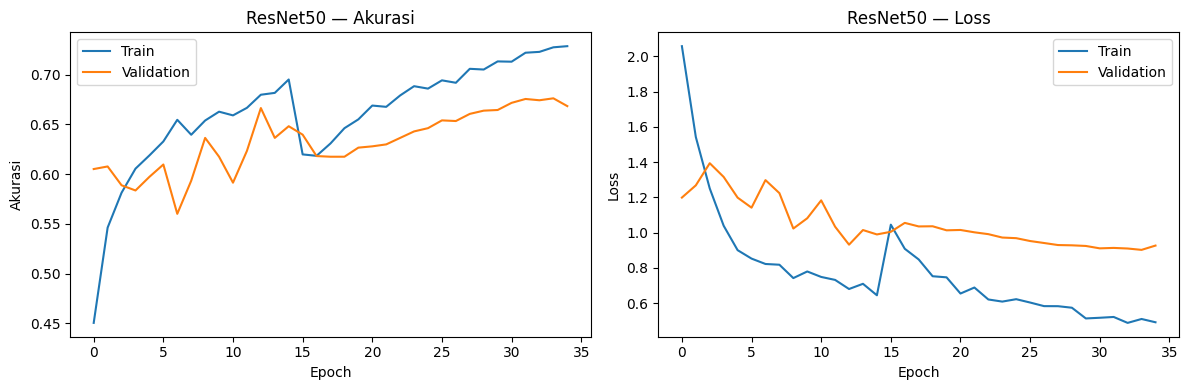


===== Hasil Evaluasi: ResNet50 =====
Akurasi         : 0.7031
Precision(macro): 0.5490
Recall (macro)  : 0.6409
F1-score(macro) : 0.5746
AUC-ROC (macro) : 0.9353

Classification report per kelas:
              precision    recall  f1-score   support

       akiec       0.62      0.54      0.58        52
         bcc       0.61      0.61      0.61        71
         bkl       0.46      0.69      0.55       167
          df       0.32      0.65      0.43        20
         mel       0.37      0.65      0.47       167
          nv       0.95      0.73      0.83      1004
        vasc       0.52      0.62      0.57        21

    accuracy                           0.70      1502
   macro avg       0.55      0.64      0.57      1502
weighted avg       0.79      0.70      0.73      1502



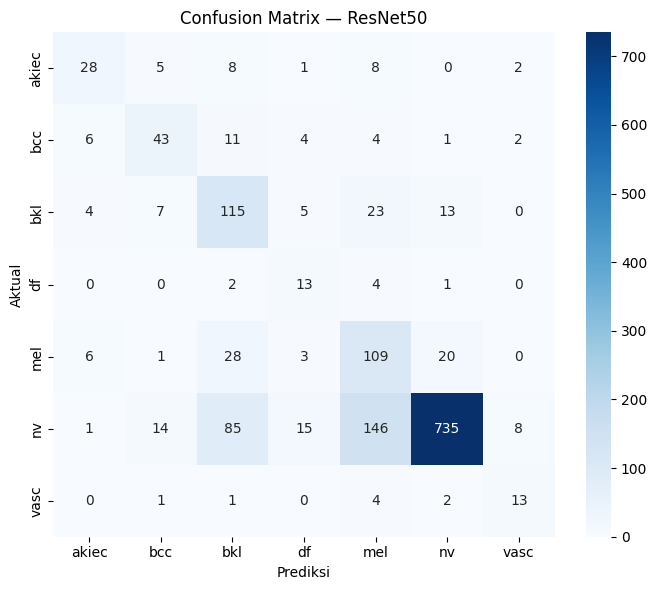

Hasil evaluasi 'ResNet50' tersimpan ke Drive.


In [ ]:
model_r, hist_r, test_ds_r = train_one_architecture('ResNet50')
plot_training_history(hist_r, 'ResNet50')
if 'ResNet50' not in all_results_dict:
    all_results_dict['ResNet50'] = evaluate_model(model_r, test_ds_r, 'ResNet50')
    all_histories['ResNet50'] = hist_r
else:
    print("Hasil evaluasi ResNet50 sudah ada, tidak dievaluasi ulang.")


TRAINING: EfficientNetB0
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
-- Tahap 1 (EfficientNetB0): jika ada backup sebelumnya, akan otomatis resume --
Epoch 1/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 219s 700ms/step - accuracy: 0.3946 - auc: 0.7692 - loss: 2.0546 - val_accuracy: 0.5966 - val_auc: 0.8646 - val_loss: 1.0630 - learning_rate: 0.0010
Epoch 2/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 150s 509ms/step - accuracy: 0.4575 - auc: 0.8325 - loss: 1.6225 - val_accuracy: 0.5659 - val_auc: 0.8705 - val_loss: 1.1266 - learning_rate: 0.0010
Epoch 3/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 148s 508ms/step - accuracy: 0.5012 - auc: 0.8605 - loss: 1.4014 - val_accuracy: 0.5483 - val_auc: 0.8773 - val_loss: 1.2505 - learning_rate: 0.0010
Epoch 4/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 202s 519ms/step - accuracy: 0.5333 - auc: 0.8740 - loss: 1.2530 - val_accuracy: 0.6299 - val_auc: 0.8819 - val_loss: 0.9623 - learning_rate: 0.0010
Epoch 5/15
219/219 ━━━━━━━━━━━━━━━━━━━━ 151s 519ms/step - accuracy: 0.5396 - auc: 0.8817 -

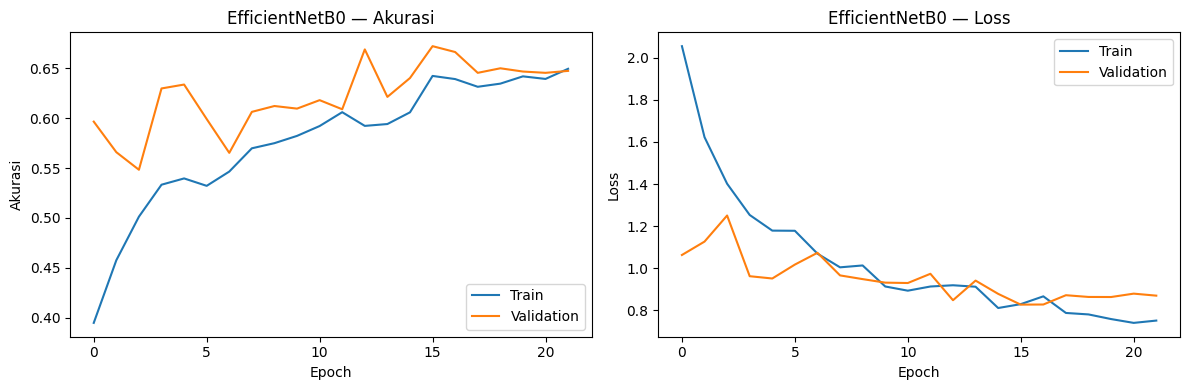


===== Hasil Evaluasi: EfficientNetB0 =====
Akurasi         : 0.7044
Precision(macro): 0.5272
Recall (macro)  : 0.6219
F1-score(macro) : 0.5627
AUC-ROC (macro) : 0.9233

Classification report per kelas:
              precision    recall  f1-score   support

       akiec       0.47      0.54      0.50        52
         bcc       0.49      0.58      0.53        71
         bkl       0.44      0.55      0.49       167
          df       0.40      0.70      0.51        20
         mel       0.35      0.54      0.43       167
          nv       0.94      0.77      0.85      1004
        vasc       0.61      0.67      0.64        21

    accuracy                           0.70      1502
   macro avg       0.53      0.62      0.56      1502
weighted avg       0.77      0.70      0.73      1502



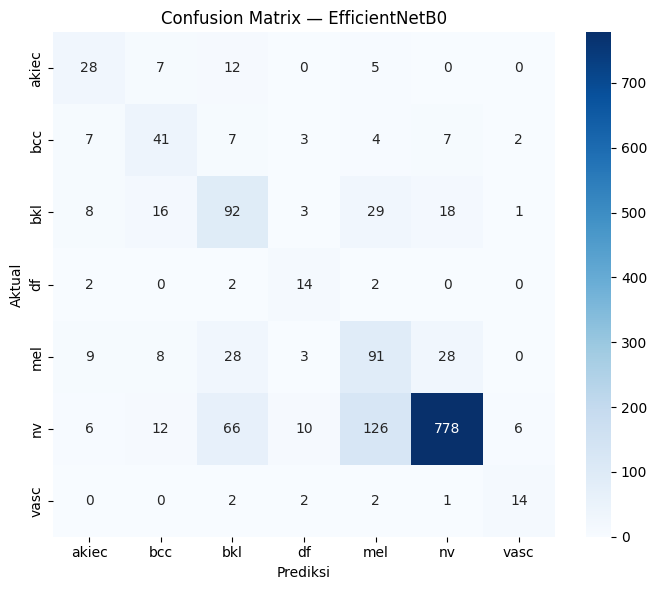

Hasil evaluasi 'EfficientNetB0' tersimpan ke Drive.


In [ ]:
model_e, hist_e, test_ds_e = train_one_architecture('EfficientNetB0')
plot_training_history(hist_e, 'EfficientNetB0')
if 'EfficientNetB0' not in all_results_dict:
    all_results_dict['EfficientNetB0'] = evaluate_model(model_e, test_ds_e, 'EfficientNetB0')
    all_histories['EfficientNetB0'] = hist_e
else:
    print("Hasil evaluasi EfficientNetB0 sudah ada, tidak dievaluasi ulang.")


'VGG16' sudah pernah selesai dilatih sebelumnya. Memuat model dari Drive, tidak dilatih ulang.


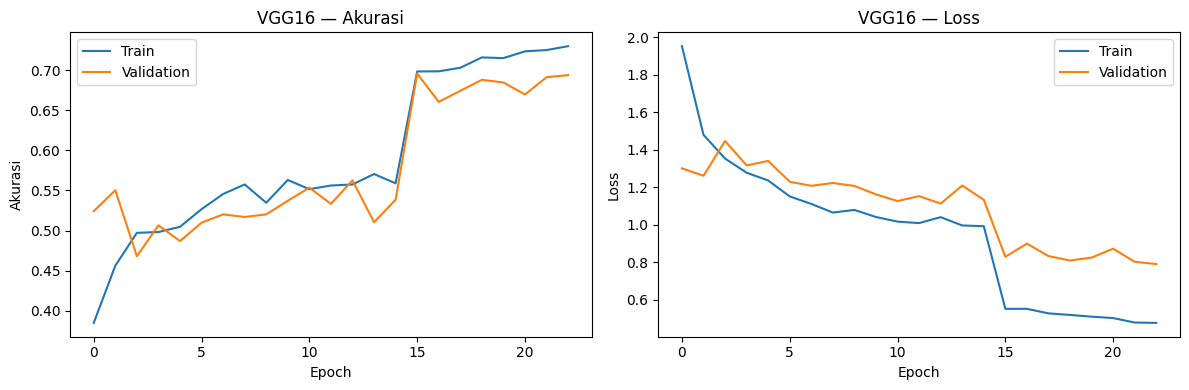


===== Hasil Evaluasi: VGG16 =====
Akurasi         : 0.7064
Precision(macro): 0.5717
Recall (macro)  : 0.6658
F1-score(macro) : 0.5858
AUC-ROC (macro) : 0.9376

Classification report per kelas:
              precision    recall  f1-score   support

       akiec       0.65      0.46      0.54        52
         bcc       0.65      0.68      0.66        71
         bkl       0.57      0.65      0.61       167
          df       0.22      0.75      0.34        20
         mel       0.35      0.68      0.46       167
          nv       0.94      0.74      0.82      1004
        vasc       0.62      0.71      0.67        21

    accuracy                           0.71      1502
   macro avg       0.57      0.67      0.59      1502
weighted avg       0.79      0.71      0.73      1502



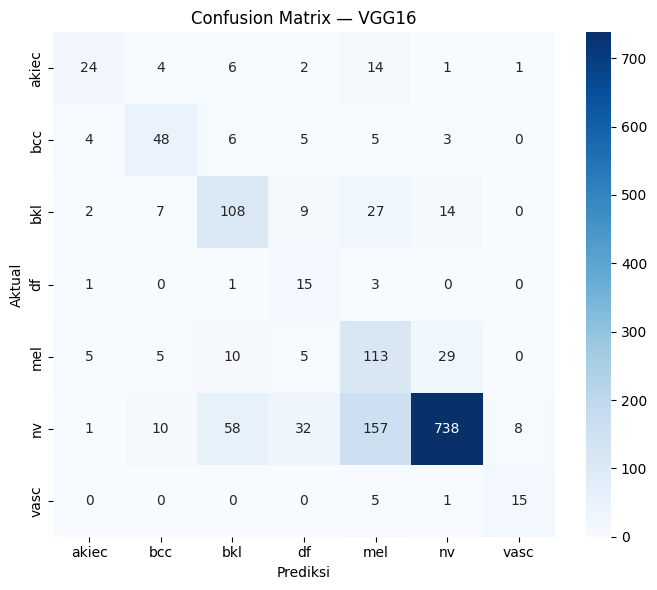

Hasil evaluasi 'VGG16' tersimpan ke Drive.


In [ ]:
model_v, hist_v, test_ds_v = train_one_architecture('VGG16')
plot_training_history(hist_v, 'VGG16')
if 'VGG16' not in all_results_dict:
    all_results_dict['VGG16'] = evaluate_model(model_v, test_ds_v, 'VGG16')
    all_histories['VGG16'] = hist_v
else:
    print("Hasil evaluasi VGG16 sudah ada, tidak dievaluasi ulang.")


         Model  Akurasi  Precision (macro)  Recall (macro)  F1-score (macro)  AUC-ROC (macro)
      ResNet50   0.7031             0.5490          0.6409            0.5746           0.9353
         VGG16   0.7064             0.5717          0.6658            0.5858           0.9376
EfficientNetB0   0.7044             0.5272          0.6219            0.5627           0.9233

Tabel tersimpan ke: /content/drive/MyDrive/Tesis_HAM10000/results/perbandingan_hasil_model.csv


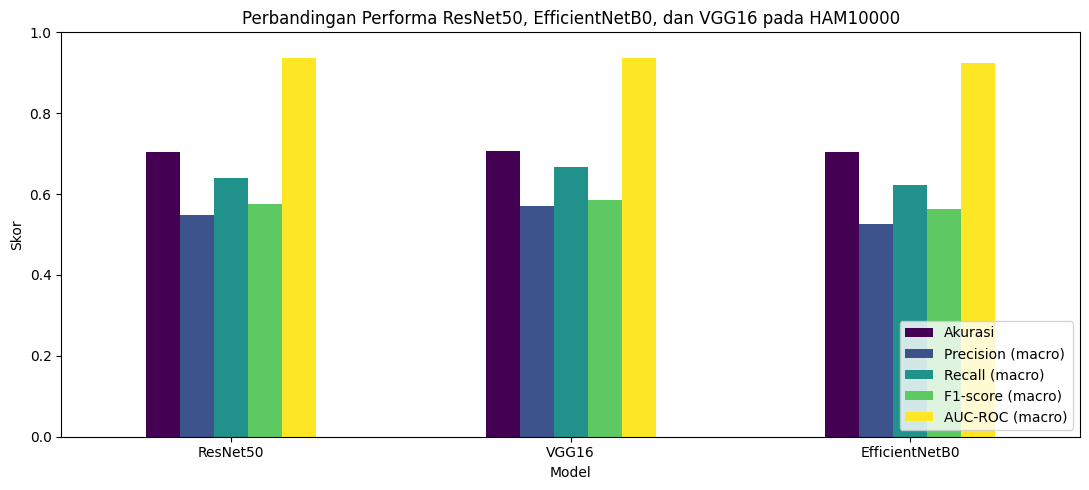

In [ ]:

if len(all_results_dict) < 3:
    missing = [m for m in ['ResNet50', 'EfficientNetB0', 'VGG16'] if m not in all_results_dict]
    print(f"⚠ Baru {len(all_results_dict)}/3 arsitektur selesai. Belum ada hasil untuk: {missing}")
    print("Tabel di bawah hanya menampilkan arsitektur yang sudah selesai.\n")

results_df = pd.DataFrame(list(all_results_dict.values()))[
    ['model', 'accuracy', 'precision_macro', 'recall_macro', 'f1_macro', 'auc_macro']
]
results_df.columns = ['Model', 'Akurasi', 'Precision (macro)', 'Recall (macro)',
                       'F1-score (macro)', 'AUC-ROC (macro)']
results_df = results_df.round(4)
print(results_df.to_string(index=False))

results_df.to_csv(f'{RESULTS_DIR}/perbandingan_hasil_model.csv', index=False)
print(f"\nTabel tersimpan ke: {RESULTS_DIR}/perbandingan_hasil_model.csv")

metrics_to_plot = ['Akurasi', 'Precision (macro)', 'Recall (macro)', 'F1-score (macro)', 'AUC-ROC (macro)']
plot_df = results_df.set_index('Model')[metrics_to_plot]

plot_df.plot(kind='bar', figsize=(11, 5), colormap='viridis')
plt.title('Perbandingan Performa ResNet50, EfficientNetB0, dan VGG16 pada HAM10000')
plt.ylabel('Skor')
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(f'{FIGS_DIR}/perbandingan_model_bar_chart.png', dpi=150)
plt.show()


In [ ]:
auc_table = pd.DataFrame({name: r['auc_per_class'] for name, r in all_results_dict.items()}).round(4)
print("AUC-ROC per kelas per model:")
print(auc_table)
auc_table.to_csv(f'{RESULTS_DIR}/auc_per_kelas.csv')
print(f"\nTersimpan ke: {RESULTS_DIR}/auc_per_kelas.csv")


AUC-ROC per kelas per model:
       ResNet50   VGG16  EfficientNetB0
akiec    0.9601  0.9681          0.9516
bcc      0.9702  0.9700          0.9466
bkl      0.8932  0.9071          0.8636
df       0.9548  0.9556          0.9638
mel      0.8697  0.8730          0.8283
nv       0.9255  0.9271          0.9163
vasc     0.9735  0.9625          0.9932

Tersimpan ke: /content/drive/MyDrive/Tesis_HAM10000/results/auc_per_kelas.csv


In [ ]:
!pip install -q tensorflow scikit-learn seaborn statsmodels

import os, json, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.applications.resnet50 import preprocess_input as pp_resnet
from tensorflow.keras.applications.efficientnet import preprocess_input as pp_efficientnet
from tensorflow.keras.applications.vgg16 import preprocess_input as pp_vgg16

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from statsmodels.stats.contingency_tables import mcnemar

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

from google.colab import drive
drive.mount('/content/drive')

BASE_DIR    = '/content/drive/MyDrive/Tesis_HAM10000'
MODEL_DIR   = f'{BASE_DIR}/models'
RESULTS_DIR = f'{BASE_DIR}/results'
FIGS_DIR    = f'{BASE_DIR}/figures'
ANALYSIS_DIR = f'{BASE_DIR}/analisis_lanjutan'
os.makedirs(ANALYSIS_DIR, exist_ok=True)

print("Direktori siap. Model yang tersedia di MODEL_DIR:")
print([f for f in os.listdir(MODEL_DIR) if f.startswith('final_')])


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Direktori siap. Model yang tersedia di MODEL_DIR:
['final_ResNet50.keras', 'final_VGG16.keras', 'final_EfficientNetB0.keras']


In [ ]:
import kagglehub
dataset_path = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")

metadata_csv = glob.glob(os.path.join(dataset_path, "**", "*metadata*.csv"), recursive=True)[0]
image_dirs = [d for d in glob.glob(os.path.join(dataset_path, "**", "*"), recursive=True)
              if os.path.isdir(d) and any(f.endswith(('.jpg', '.jpeg')) for f in os.listdir(d)[:5] if os.path.isfile(os.path.join(d, f)))]

image_path_map = {}
for d in image_dirs:
    for fname in os.listdir(d):
        if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
            image_path_map[os.path.splitext(fname)[0]] = os.path.join(d, fname)

df = pd.read_csv(metadata_csv)
df['path'] = df['image_id'].map(image_path_map)
df = df.dropna(subset=['path']).reset_index(drop=True)

CLASS_NAMES = ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
LABEL2IDX = {c: i for i, c in enumerate(CLASS_NAMES)}
IDX2LABEL = {i: c for c, i in LABEL2IDX.items()}
df['label'] = df['dx'].map(LABEL2IDX)

lesion_df = df.groupby('lesion_id')['label'].agg(lambda x: x.mode()[0]).reset_index()
train_lesions, temp_lesions = train_test_split(
    lesion_df, test_size=0.30, stratify=lesion_df['label'], random_state=SEED
)
val_lesions, test_lesions = train_test_split(
    temp_lesions, test_size=0.50, stratify=temp_lesions['label'], random_state=SEED
)
test_df = df[df['lesion_id'].isin(test_lesions['lesion_id'])].reset_index(drop=True)

print(f"Test set: {len(test_df)} citra ({len(test_lesions)} lesi) — harus sama dengan angka saat training awal.")
print(test_df['dx'].value_counts())


Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
Test set: 1502 citra (1121 lesi) — harus sama dengan angka saat training awal.
dx
nv       1004
mel       167
bkl       167
bcc        71
akiec      52
vasc       21
df         20
Name: count, dtype: int64


In [ ]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = len(CLASS_NAMES)
AUTOTUNE = tf.data.AUTOTUNE

MODEL_CONFIGS = {
    'ResNet50': {'preprocess': pp_resnet},
    'EfficientNetB0': {'preprocess': pp_efficientnet},
    'VGG16': {'preprocess': pp_vgg16},
}

def load_and_decode(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    return img, label

def make_test_dataset(dataframe, preprocess_fn):
    paths = dataframe['path'].values
    labels = tf.keras.utils.to_categorical(dataframe['label'].values, num_classes=NUM_CLASSES)
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_and_decode, num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (preprocess_fn(x), y), num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)
    return ds

y_true_idx = test_df['label'].values

predictions = {}
pred_labels = {}
correctness = {}

for model_name, cfg in MODEL_CONFIGS.items():
    fpath = f'{MODEL_DIR}/final_{model_name}.keras'
    print(f"Memuat {model_name} ...")
    model = tf.keras.models.load_model(fpath)
    test_ds = make_test_dataset(test_df, cfg['preprocess'])
    probs = model.predict(test_ds, verbose=0)
    preds = np.argmax(probs, axis=1)

    predictions[model_name] = probs
    pred_labels[model_name] = preds
    correctness[model_name] = (preds == y_true_idx)

    acc = correctness[model_name].mean()
    print(f"  -> akurasi test set: {acc:.4f}")
    del model
    tf.keras.backend.clear_session()

print("\nSemua model selesai diprediksi pada test set yang identik.")


Memuat ResNet50 ...
  -> akurasi test set: 0.7031
Memuat EfficientNetB0 ...
  -> akurasi test set: 0.7044
Memuat VGG16 ...
  -> akurasi test set: 0.7064

Semua model selesai diprediksi pada test set yang identik.


In [ ]:
def run_mcnemar(name_a, name_b):
    correct_a = correctness[name_a]
    correct_b = correctness[name_b]

    n11 = np.sum(correct_a & correct_b)
    n10 = np.sum(correct_a & ~correct_b)
    n01 = np.sum(~correct_a & correct_b)
    n00 = np.sum(~correct_a & ~correct_b)
    table = [[n11, n10], [n01, n00]]

    use_exact = (n10 + n01) < 25
    result = mcnemar(table, exact=use_exact, correction=not use_exact)

    return {
        'pasangan': f'{name_a} vs {name_b}',
        'n_keduanya_benar': int(n11),
        f'n_{name_a}_benar_{name_b}_salah': int(n10),
        f'n_{name_a}_salah_{name_b}_benar': int(n01),
        'n_keduanya_salah': int(n00),
        'statistic': float(result.statistic),
        'p_value': float(result.pvalue),
        'signifikan (p<0.05)': bool(result.pvalue < 0.05),
    }

pairs = [('ResNet50', 'EfficientNetB0'), ('ResNet50', 'VGG16'), ('EfficientNetB0', 'VGG16')]
mcnemar_results = [run_mcnemar(a, b) for a, b in pairs]

for r in mcnemar_results:
    print(f"\n=== {r['pasangan']} ===")
    for k, v in r.items():
        if k != 'pasangan':
            print(f"  {k}: {v}")
    verdict = "SIGNIFIKAN — perbedaan performa kedua model bukan kebetulan" if r['signifikan (p<0.05)'] \
              else "TIDAK signifikan — perbedaan performa bisa jadi hanya variasi acak"
    print(f"  >> Kesimpulan: {verdict}")

mcnemar_df = pd.DataFrame(mcnemar_results)
mcnemar_df.to_csv(f'{ANALYSIS_DIR}/mcnemar_test_results.csv', index=False)
print(f"\nTersimpan ke: {ANALYSIS_DIR}/mcnemar_test_results.csv")



=== ResNet50 vs EfficientNetB0 ===
  n_keduanya_benar: 894
  n_ResNet50_benar_EfficientNetB0_salah: 162
  n_ResNet50_salah_EfficientNetB0_benar: 164
  n_keduanya_salah: 282
  statistic: 0.003067484662576687
  p_value: 0.9558318433019074
  signifikan (p<0.05): False
  >> Kesimpulan: TIDAK signifikan — perbedaan performa bisa jadi hanya variasi acak

=== ResNet50 vs VGG16 ===
  n_keduanya_benar: 923
  n_ResNet50_benar_VGG16_salah: 133
  n_ResNet50_salah_VGG16_benar: 138
  n_keduanya_salah: 308
  statistic: 0.05904059040590406
  p_value: 0.8080188026382749
  signifikan (p<0.05): False
  >> Kesimpulan: TIDAK signifikan — perbedaan performa bisa jadi hanya variasi acak

=== EfficientNetB0 vs VGG16 ===
  n_keduanya_benar: 890
  n_EfficientNetB0_benar_VGG16_salah: 168
  n_EfficientNetB0_salah_VGG16_benar: 171
  n_keduanya_salah: 273
  statistic: 0.011799410029498525
  p_value: 0.9134998601027751
  signifikan (p<0.05): False
  >> Kesimpulan: TIDAK signifikan — perbedaan performa bisa jadi han

In [ ]:
def top_confused_pairs(model_name, top_k=5):
    cm = confusion_matrix(y_true_idx, pred_labels[model_name])
    pairs = []
    for i in range(len(CLASS_NAMES)):
        for j in range(len(CLASS_NAMES)):
            if i != j and cm[i, j] > 0:
                pairs.append((CLASS_NAMES[i], CLASS_NAMES[j], cm[i, j]))
    pairs.sort(key=lambda x: -x[2])
    return pairs[:top_k]

confusion_summary = {}
for model_name in MODEL_CONFIGS.keys():
    top_pairs = top_confused_pairs(model_name, top_k=5)
    confusion_summary[model_name] = top_pairs
    print(f"\n=== {model_name}: 5 pasangan kelas paling sering tertukar ===")
    print(f"{'Aktual':8s} -> {'Diprediksi':10s} : Jumlah kasus")
    for actual, predicted, count in top_pairs:
        print(f"{actual:8s} -> {predicted:10s} : {count}")


rows = []
for model_name, pairs in confusion_summary.items():
    for actual, predicted, count in pairs:
        rows.append({'model': model_name, 'kelas_aktual': actual, 'diprediksi_sebagai': predicted, 'jumlah': count})
confused_df = pd.DataFrame(rows)
confused_df.to_csv(f'{ANALYSIS_DIR}/top_confused_pairs.csv', index=False)
print(f"\nTersimpan ke: {ANALYSIS_DIR}/top_confused_pairs.csv")



=== ResNet50: 5 pasangan kelas paling sering tertukar ===
Aktual   -> Diprediksi : Jumlah kasus
nv       -> mel        : 146
nv       -> bkl        : 85
mel      -> bkl        : 28
bkl      -> mel        : 23
mel      -> nv         : 20

=== EfficientNetB0: 5 pasangan kelas paling sering tertukar ===
Aktual   -> Diprediksi : Jumlah kasus
nv       -> mel        : 126
nv       -> bkl        : 66
bkl      -> mel        : 29
mel      -> bkl        : 28
mel      -> nv         : 28

=== VGG16: 5 pasangan kelas paling sering tertukar ===
Aktual   -> Diprediksi : Jumlah kasus
nv       -> mel        : 157
nv       -> bkl        : 58
nv       -> df         : 32
mel      -> nv         : 29
bkl      -> mel        : 27

Tersimpan ke: /content/drive/MyDrive/Tesis_HAM10000/analisis_lanjutan/top_confused_pairs.csv


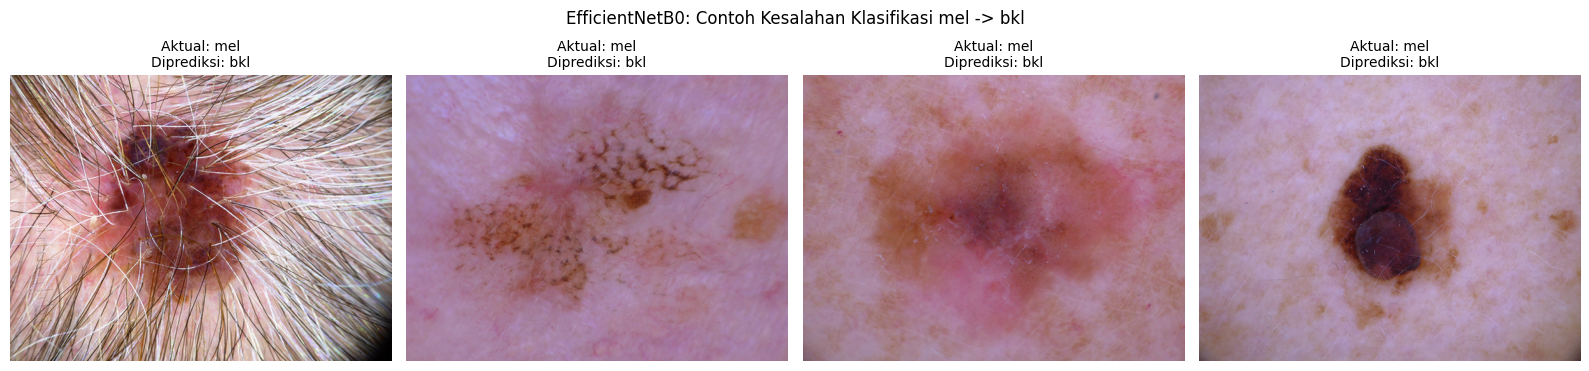

Tersimpan ke: /content/drive/MyDrive/Tesis_HAM10000/analisis_lanjutan/contoh_salah_EfficientNetB0_mel_ke_bkl.png


In [ ]:
def show_misclassified_examples(model_name, actual_class, predicted_class, n_examples=4):
    actual_idx = LABEL2IDX[actual_class]
    predicted_idx = LABEL2IDX[predicted_class]

    mask = (y_true_idx == actual_idx) & (pred_labels[model_name] == predicted_idx)
    examples = test_df[mask].head(n_examples)

    if len(examples) == 0:
        print(f"Tidak ditemukan contoh {actual_class} -> {predicted_class} untuk {model_name}.")
        return

    fig, axes = plt.subplots(1, len(examples), figsize=(4 * len(examples), 4))
    if len(examples) == 1:
        axes = [axes]
    for ax, (_, row) in zip(axes, examples.iterrows()):
        img = tf.io.read_file(row['path'])
        img = tf.image.decode_jpeg(img, channels=3)
        ax.imshow(img.numpy())
        ax.set_title(f"Aktual: {actual_class}\nDiprediksi: {predicted_class}", fontsize=10)
        ax.axis('off')
    plt.suptitle(f'{model_name}: Contoh Kesalahan Klasifikasi {actual_class} -> {predicted_class}')
    plt.tight_layout()
    fname = f'{ANALYSIS_DIR}/contoh_salah_{model_name}_{actual_class}_ke_{predicted_class}.png'
    plt.savefig(fname, dpi=150)
    plt.show()
    print(f"Tersimpan ke: {fname}")

show_misclassified_examples('EfficientNetB0', 'mel', 'bkl', n_examples=4)


ResNet50: rata-rata gap train-val accuracy (5 epoch terakhir) = 0.0496 -> gap wajar
EfficientNetB0: rata-rata gap train-val accuracy (5 epoch terakhir) = -0.0076 -> gap wajar
VGG16: rata-rata gap train-val accuracy (5 epoch terakhir) = 0.0364 -> gap wajar


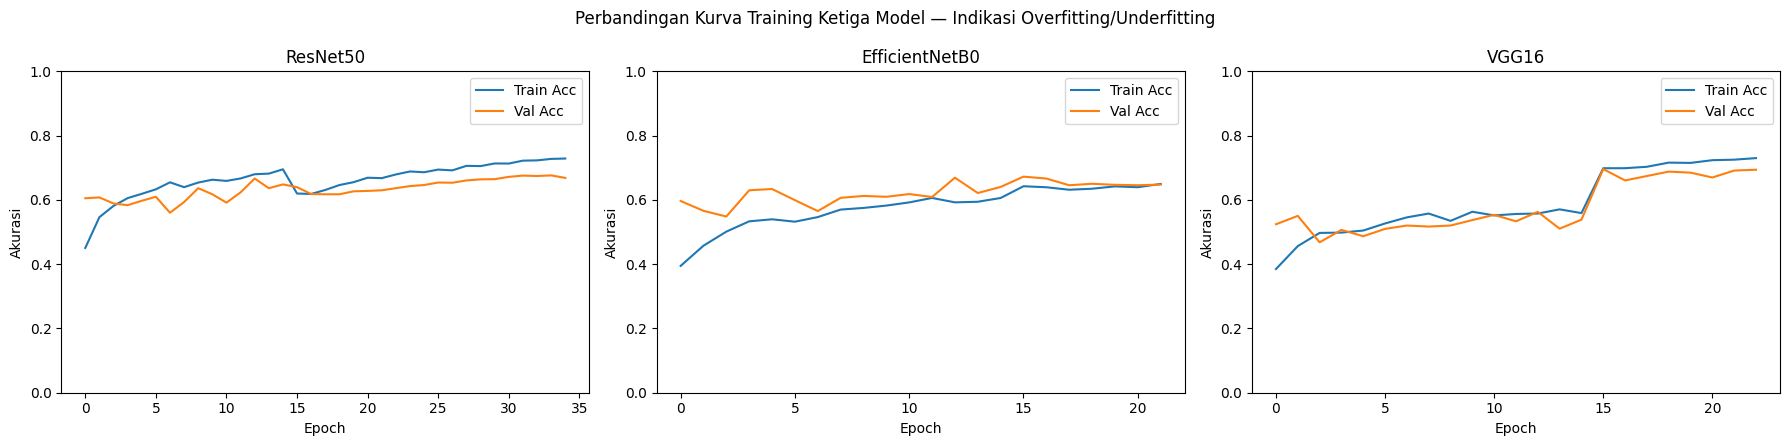

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

for ax, model_name in zip(axes, MODEL_CONFIGS.keys()):
    history_path = f'{RESULTS_DIR}/{model_name}_history.json'
    if not os.path.exists(history_path):
        ax.set_title(f'{model_name}: histori tidak ditemukan')
        continue
    hist = json.load(open(history_path))
    ax.plot(hist['accuracy'], label='Train Acc')
    ax.plot(hist['val_accuracy'], label='Val Acc')
    ax.set_title(model_name)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Akurasi')
    ax.legend()
    ax.set_ylim(0, 1)

    gap = np.array(hist['accuracy'][-5:]).mean() - np.array(hist['val_accuracy'][-5:]).mean()
    print(f"{model_name}: rata-rata gap train-val accuracy (5 epoch terakhir) = {gap:.4f}"
          f" -> {'indikasi overfitting ringan-sedang' if gap > 0.10 else 'gap wajar'}")

plt.suptitle('Perbandingan Kurva Training Ketiga Model — Indikasi Overfitting/Underfitting')
plt.tight_layout()
plt.savefig(f'{ANALYSIS_DIR}/perbandingan_kurva_training.png', dpi=150)
plt.show()


In [ ]:
final_results = {}
for model_name in MODEL_CONFIGS.keys():
    result_path = f'{RESULTS_DIR}/{model_name}_result.json'
    if os.path.exists(result_path):
        final_results[model_name] = json.load(open(result_path))

own_rows = []
for model_name, r in final_results.items():
    own_rows.append({
        'Sumber': 'Penelitian ini',
        'Model': model_name,
        'Akurasi': round(r['accuracy'], 4),
        'AUC-ROC (macro)': round(r['auc_macro'], 4) if r['auc_macro'] else None,
        'Skema Split': "Stratified 70:15:15, level lesion_id (mencegah data leakage)",
        'Catatan': ''
    })

literature_template = [
    {'Sumber': 'Nugroho et al. (2020) - arXiv:2009.05977', 'Model': 'ResNet50 (dgn focal loss + class-weighted)',
     'Akurasi': 0.93, 'AUC-ROC (macro)': None,
     'Skema Split': 'Tidak disebutkan eksplisit (kemungkinan besar image-level)',
     'Catatan': 'ResNet50 unggul dibanding VGG16, MobileNet, EfficientNetB1 pada studi ini; teknik class-weighted mirip penelitian ini'},
    {'Sumber': 'SkinCancerNet, IIETA (Trans. Sci.)', 'Model': 'VGG16 (VGGNet16)',
     'Akurasi': 0.9328, 'AUC-ROC (macro)': None,
     'Skema Split': 'Tidak disebutkan eksplisit', 'Catatan': 'Arsitektur tunggal, transfer learning dari ImageNet'},
    {'Sumber': 'SkinCancerNet, IIETA (Trans. Sci.)', 'Model': 'ResNet50',
     'Akurasi': 0.8710, 'AUC-ROC (macro)': None,
     'Skema Split': 'Tidak disebutkan eksplisit', 'Catatan': 'Arsitektur tunggal, transfer learning dari ImageNet'},
    {'Sumber': 'Bechelli & Delhommelle (dikutip dlm review PMC10252190)', 'Model': 'VGG16',
     'Akurasi': 0.70, 'AUC-ROC (macro)': None,
     'Skema Split': 'Tidak disebutkan eksplisit',
     'Catatan': 'PENTING: performa deep learning pada HAM10000 dilaporkan rendah pada studi ini - akurasi VGG16 (model terbaik mereka) SANGAT DEKAT dengan ResNet50 penelitian ini (0.70 vs hasil Anda). Memperkuat argumen bahwa hasil penelitian ini realistis, bukan anomali.'},
    {'Sumber': 'Garg et al. (dikutip dlm review arXiv:2401.04746)', 'Model': 'ResNet50',
     'Akurasi': 0.9051, 'AUC-ROC (macro)': None,
     'Skema Split': 'Tidak disebutkan eksplisit',
     'Catatan': 'VGG16 & ResNet50 sbg feature extractor + meta-learner (Random Forest, XGBoost, SVM)'},
    {'Sumber': 'Ismail et al. (dikutip dlm review arXiv:2401.04746)', 'Model': 'ResNet50+VGG16+DenseNet (stacking)',
     'Akurasi': 0.8401, 'AUC-ROC (macro)': None,
     'Skema Split': 'Tidak disebutkan eksplisit',
     'Catatan': 'Model gabungan (stacking 3 arsitektur) - bukan perbandingan arsitektur tunggal, tidak apple-to-apple'},
    {'Sumber': 'Krishna et al. - BILSK, ScienceDirect (2021)', 'Model': 'Bilinear ResNet50+VGG16',
     'Akurasi': 0.9321, 'AUC-ROC (macro)': 0.9810,
     'Skema Split': 'Tidak disebutkan eksplisit',
     'Catatan': 'Model gabungan (bilinear CNN) - bukan arsitektur tunggal, tidak apple-to-apple. Waktu training 238.6 menit'},
]

comparison_df = pd.DataFrame(own_rows + literature_template)
comparison_df.to_csv(f'{ANALYSIS_DIR}/template_perbandingan_literatur.csv', index=False)
print("Template tabel perbandingan literatur ")
print(comparison_df.to_string(index=False))
print(f"\nTersimpan ke: {ANALYSIS_DIR}/template_perbandingan_literatur.csv")


Template tabel perbandingan literatur 
                                                 Sumber                                      Model  Akurasi  AUC-ROC (macro)                                                  Skema Split                                                                                                                                                                                                                                                         Catatan
                                         Penelitian ini                                   ResNet50   0.7031           0.9353 Stratified 70:15:15, level lesion_id (mencegah data leakage)                                                                                                                                                                                                                                                                
                                         Penelitian ini                      

/tmp/ipykernel_1753/4203416360.py:105: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  jet = cm.get_cmap("jet")(np.arange(256))[:, :3]


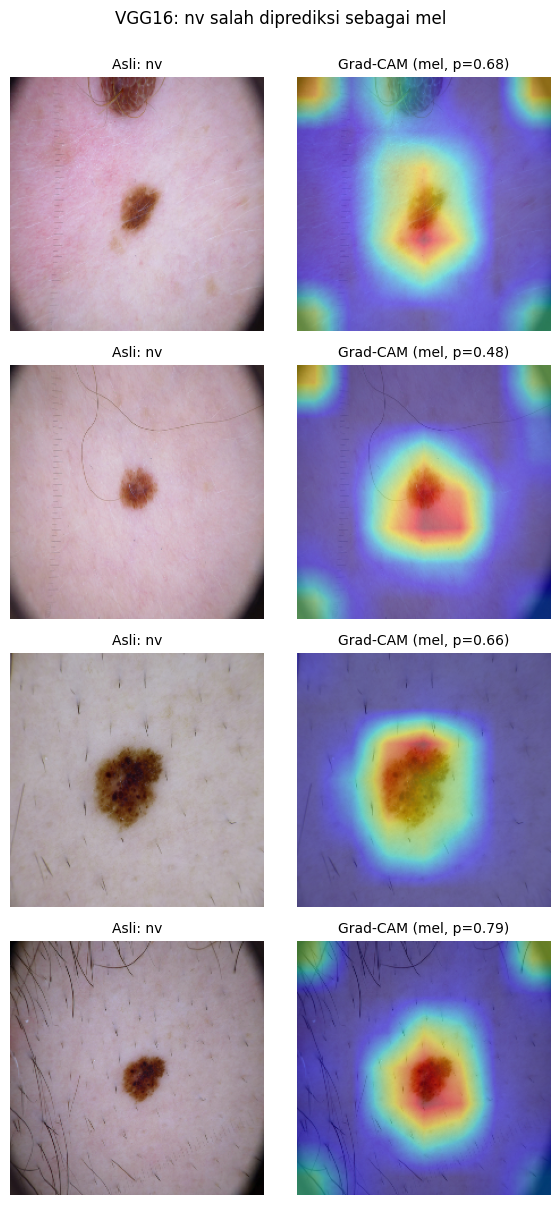

Tersimpan: /content/drive/MyDrive/Tesis_HAM10000/gradcam/gradcam_VGG16_nv_ke_mel.png


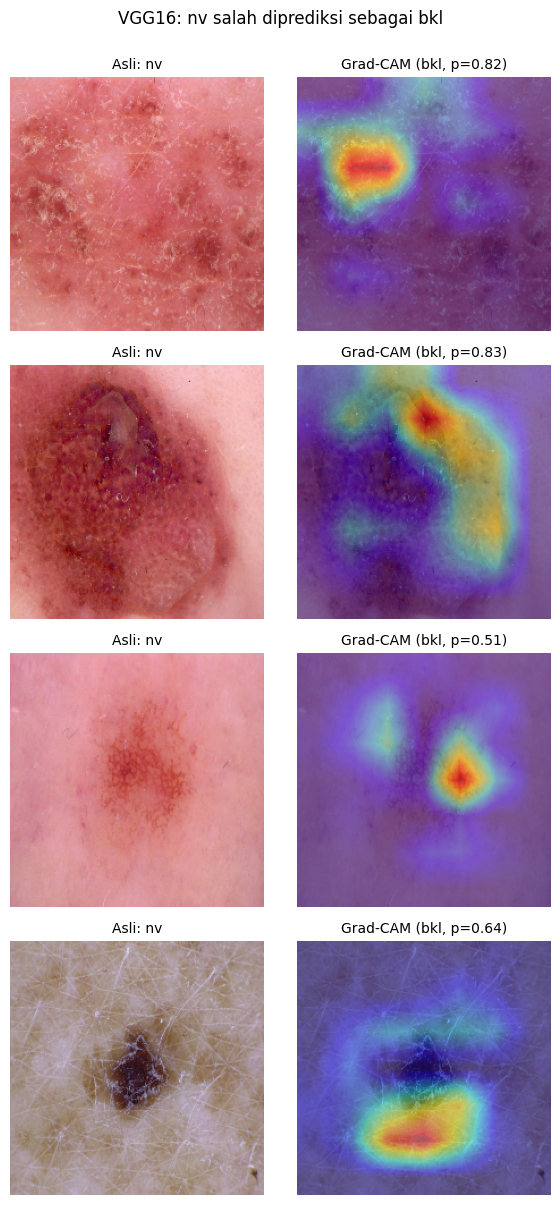

Tersimpan: /content/drive/MyDrive/Tesis_HAM10000/gradcam/gradcam_VGG16_nv_ke_bkl.png


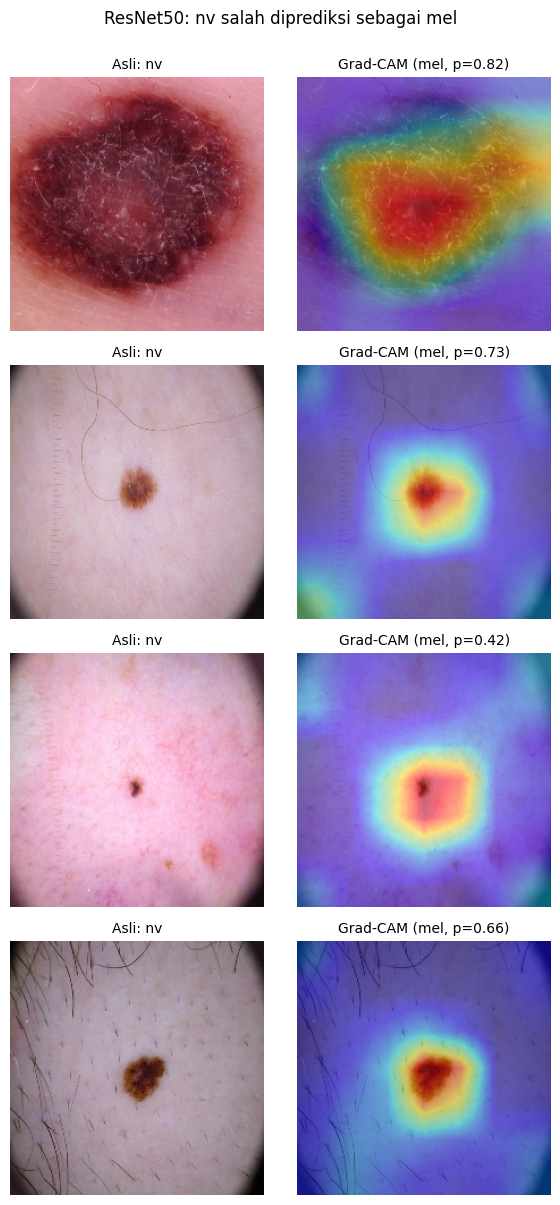

Tersimpan: /content/drive/MyDrive/Tesis_HAM10000/gradcam/gradcam_ResNet50_nv_ke_mel.png


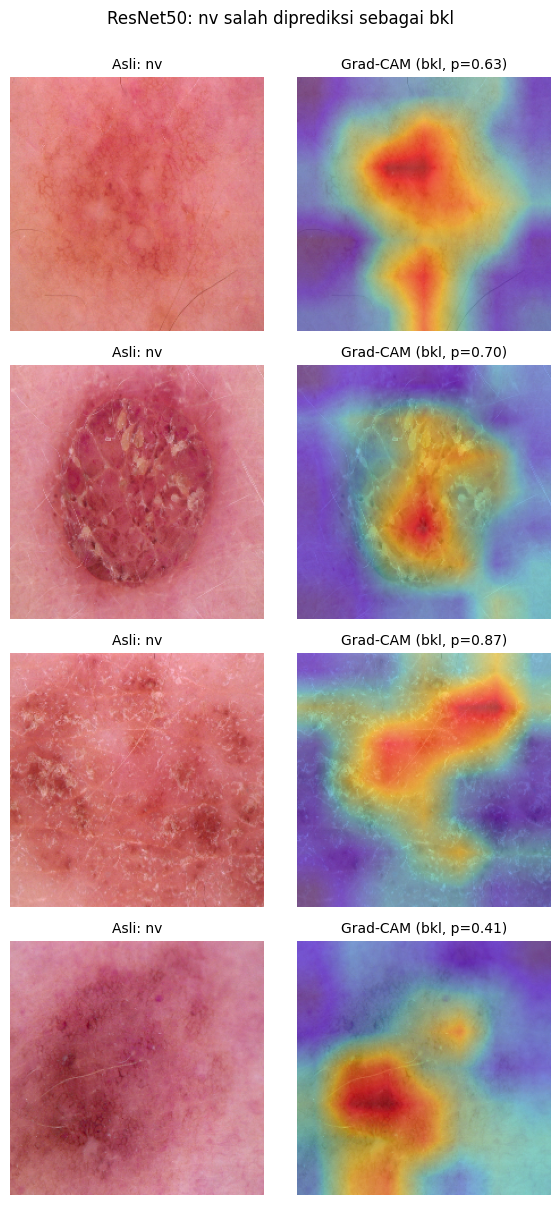

Tersimpan: /content/drive/MyDrive/Tesis_HAM10000/gradcam/gradcam_ResNet50_nv_ke_bkl.png


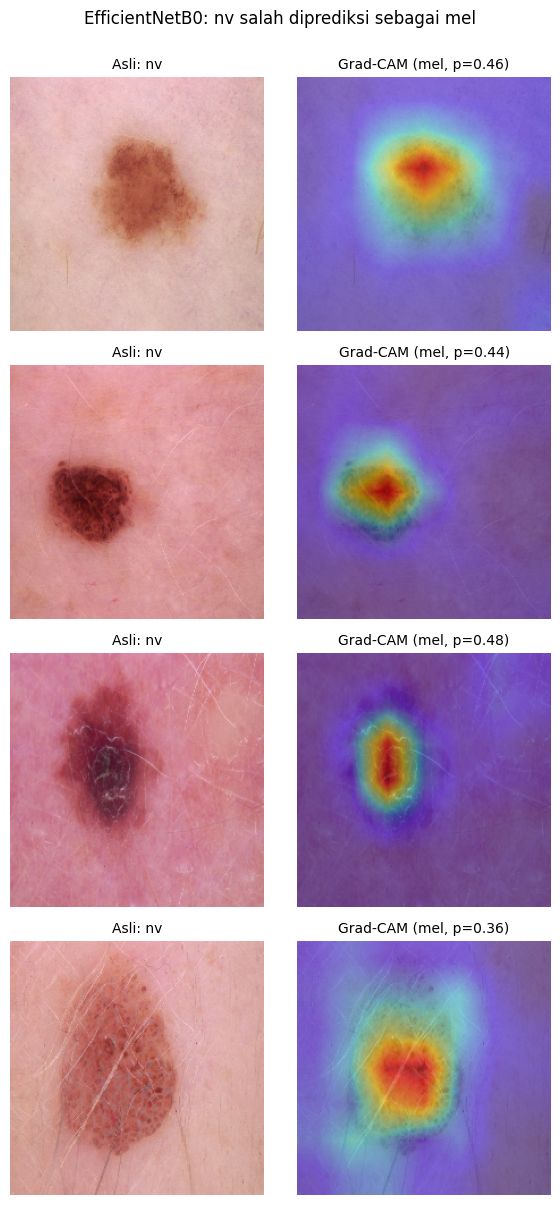

Tersimpan: /content/drive/MyDrive/Tesis_HAM10000/gradcam/gradcam_EfficientNetB0_nv_ke_mel.png


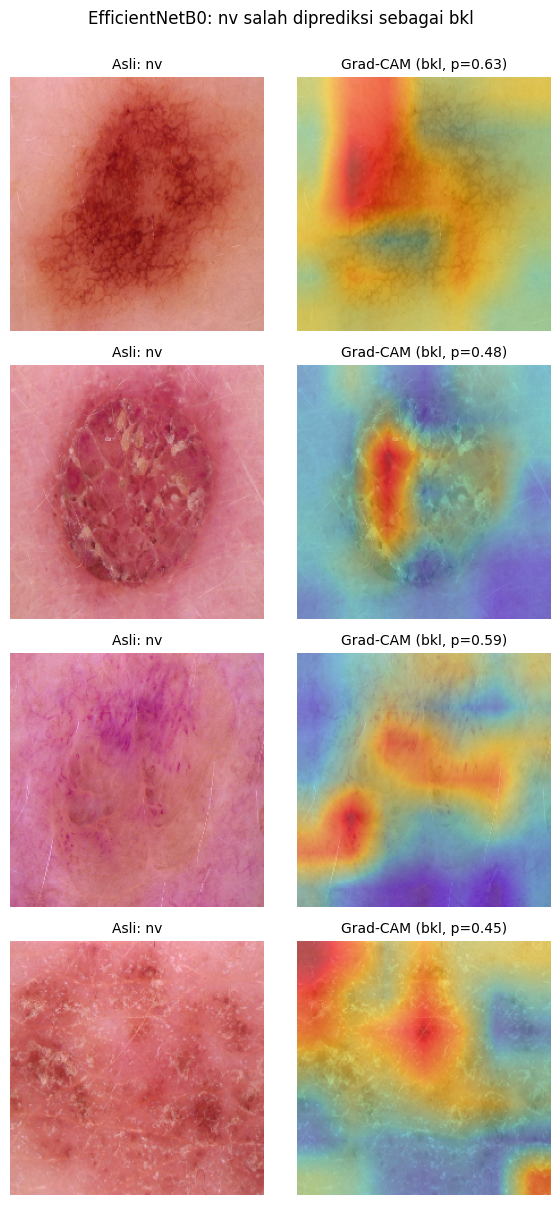

Tersimpan: /content/drive/MyDrive/Tesis_HAM10000/gradcam/gradcam_EfficientNetB0_nv_ke_bkl.png


In [ ]:

# ============================================================================

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.cm as cm

# --- direktori luaran ---
GRADCAM_DIR = f'{BASE_DIR}/gradcam'
os.makedirs(GRADCAM_DIR, exist_ok=True)

# --- LABEL2IDX dari IDX2LABEL ---
LABEL2IDX = {v: k for k, v in IDX2LABEL.items()}



def split_base_and_head(model):
    base_model, base_idx = None, None
    for i, layer in enumerate(model.layers):
        if isinstance(layer, tf.keras.Model):
            base_model, base_idx = layer, i
            break
    if base_model is None:
        raise ValueError(
            "Base model (nested) tidak ditemukan. Pastikan model dibuat "
            "dengan build_model() dari notebook training."
        )
    head_layers = model.layers[base_idx + 1:]          # GAP, BN, Dropout, Dense, ...
    return base_model, head_layers



def make_gradcam_heatmap(img_array, base_model, head_layers, class_index):
    conv_submodel = tf.keras.Model(base_model.input, base_model.output)

    last_dense = head_layers[-1]
    saved_activation = last_dense.activation
    last_dense.activation = tf.keras.activations.linear   # -> logit

    try:
        with tf.GradientTape() as tape:
            conv_out = conv_submodel(img_array, training=False)   # (1,H,W,C)
            tape.watch(conv_out)
            x = conv_out
            for layer in head_layers:
                x = layer(x, training=False)
            logits = x                                            # (1,num_classes)
            class_channel = logits[:, class_index]
        grads = tape.gradient(class_channel, conv_out)            # (1,H,W,C)
    finally:
        last_dense.activation = saved_activation                 # kembalikan softmax

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))         # (C,)
    conv_out = conv_out[0]                                        # (H,W,C)
    heatmap = conv_out @ pooled_grads[..., tf.newaxis]           # (H,W,1)
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

def load_display_and_input(path, preprocess_fn):
    raw = tf.io.read_file(path)
    img = tf.image.decode_jpeg(raw, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    disp = tf.cast(tf.clip_by_value(img, 0, 255), tf.uint8).numpy()
    inp = preprocess_fn(tf.expand_dims(tf.identity(img), 0))
    return disp, inp


def overlay_heatmap(disp_img, heatmap, alpha=0.45):
    h, w = disp_img.shape[0], disp_img.shape[1]
    hm = tf.image.resize(heatmap[..., np.newaxis], (h, w)).numpy().squeeze()
    hm_uint8 = np.uint8(255 * hm)
    jet = cm.get_cmap("jet")(np.arange(256))[:, :3]
    jet_hm = jet[hm_uint8]
    out = jet_hm * alpha + (disp_img / 255.0) * (1 - alpha)
    return np.clip(out, 0, 1)



def gradcam_untuk_pasangan(model_name, true_label, pred_label,
                           n_contoh=4, target='pred'):
    """
    target='pred' -> Grad-CAM utk kelas yang salah diprediksi (default, utk analisis kegagalan)
    target='true' -> Grad-CAM utk kelas sebenarnya (menunjukkan apa yg 'terlewat' model)
    """
    cfg = MODEL_CONFIGS[model_name]
    model = tf.keras.models.load_model(f'{MODEL_DIR}/final_{model_name}.keras')
    base_model, head_layers = split_base_and_head(model)

    true_idx, pred_idx = LABEL2IDX[true_label], LABEL2IDX[pred_label]


    subset = test_df[test_df['label'] == true_idx].reset_index(drop=True)


    disp_list, inp_list = [], []
    for p in subset['path'].values:
        d, inp = load_display_and_input(p, cfg['preprocess'])
        disp_list.append(d); inp_list.append(inp)
    inp_batch = tf.concat(inp_list, axis=0)
    probs = model.predict(inp_batch, verbose=0)
    preds = probs.argmax(axis=1)

    salah_idx = np.where(preds == pred_idx)[0]
    if len(salah_idx) == 0:
        print(f"[{model_name}] Tidak ada contoh {true_label}->{pred_label}.")
        return
    salah_idx = salah_idx[:n_contoh]

    fig, axes = plt.subplots(len(salah_idx), 2, figsize=(6, 3 * len(salah_idx)))
    if len(salah_idx) == 1:
        axes = axes[np.newaxis, :]

    cam_class = pred_idx if target == 'pred' else true_idx
    for row, si in enumerate(salah_idx):
        disp = disp_list[si]
        heatmap = make_gradcam_heatmap(inp_list[si], base_model, head_layers, cam_class)
        overlay = overlay_heatmap(disp, heatmap)
        conf = probs[si][pred_idx]

        axes[row, 0].imshow(disp); axes[row, 0].axis('off')
        axes[row, 0].set_title(f"Asli: {true_label}", fontsize=10)
        axes[row, 1].imshow(overlay); axes[row, 1].axis('off')
        axes[row, 1].set_title(f"Grad-CAM ({pred_label}, p={conf:.2f})", fontsize=10)

    fig.suptitle(f"{model_name}: {true_label} salah diprediksi sebagai {pred_label}",
                 fontsize=12, y=1.00)
    plt.tight_layout()
    out_path = f'{GRADCAM_DIR}/gradcam_{model_name}_{true_label}_ke_{pred_label}.png'
    plt.savefig(out_path, dpi=150, bbox_inches='tight')
    plt.show()
    print(f"Tersimpan: {out_path}")


# ---------------------------------------------------------------------------
# 5) Jalankan untuk pasangan kesalahan dominan.
#    Ubah daftar di bawah sesuai kebutuhan figur paper Anda.
# ---------------------------------------------------------------------------
if __name__ == "__main__":
    for model_name in ['VGG16', 'ResNet50', 'EfficientNetB0']:
        gradcam_untuk_pasangan(model_name, 'nv', 'mel', n_contoh=4)
        gradcam_untuk_pasangan(model_name, 'nv', 'bkl', n_contoh=4)


In [ ]:
import numpy as np
from sklearn.metrics import confusion_matrix

# Hitung ulang prediksi dari model tersimpan jika 'predictions' belum ada
try:
    predictions
except NameError:
    predictions = {}
    for m, cfg in MODEL_CONFIGS.items():
        model = tf.keras.models.load_model(f'{MODEL_DIR}/final_{m}.keras')
        ds = make_dataset(test_df, cfg['preprocess'], training=False)
        predictions[m] = model.predict(ds, verbose=0)

y_true = test_df['label'].values
for m in ['ResNet50', 'EfficientNetB0', 'VGG16']:
    cm = confusion_matrix(y_true, np.argmax(predictions[m], axis=1))
    print(f"=== {m} ===")
    print(np.array2string(cm, separator=','))

=== ResNet50 ===
[[ 28,  5,  8,  1,  8,  0,  2],
 [  6, 43, 11,  4,  4,  1,  2],
 [  4,  7,115,  5, 23, 13,  0],
 [  0,  0,  2, 13,  4,  1,  0],
 [  6,  1, 28,  3,109, 20,  0],
 [  1, 14, 85, 15,146,735,  8],
 [  0,  1,  1,  0,  4,  2, 13]]
=== EfficientNetB0 ===
[[ 28,  7, 12,  0,  5,  0,  0],
 [  7, 41,  7,  3,  4,  7,  2],
 [  8, 16, 92,  3, 29, 18,  1],
 [  2,  0,  2, 14,  2,  0,  0],
 [  9,  8, 28,  3, 91, 28,  0],
 [  6, 12, 66, 10,126,778,  6],
 [  0,  0,  2,  2,  2,  1, 14]]
=== VGG16 ===
[[ 24,  4,  6,  2, 14,  1,  1],
 [  4, 48,  6,  5,  5,  3,  0],
 [  2,  7,108,  9, 27, 14,  0],
 [  1,  0,  1, 15,  3,  0,  0],
 [  5,  5, 10,  5,113, 29,  0],
 [  1, 10, 58, 32,157,738,  8],
 [  0,  0,  0,  0,  5,  1, 15]]
